Dataset Shape: (569, 30)
Features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']

First 10 Radius Values:
[17.99 20.57 19.69 11.42 20.29 12.45 18.25 13.71 13.   12.46]

Sample Membership Values:
8 0
12 0.2
15 0.5
18 0.8
20 1

Defuzzification Results
-----------------------------
Centroid (COG): 50.0
Bisector: 49
Mean of Maximum (MOM): 50.0
Smallest of Maximum (SOM): 50
Largest of Maximum (LOM): 50


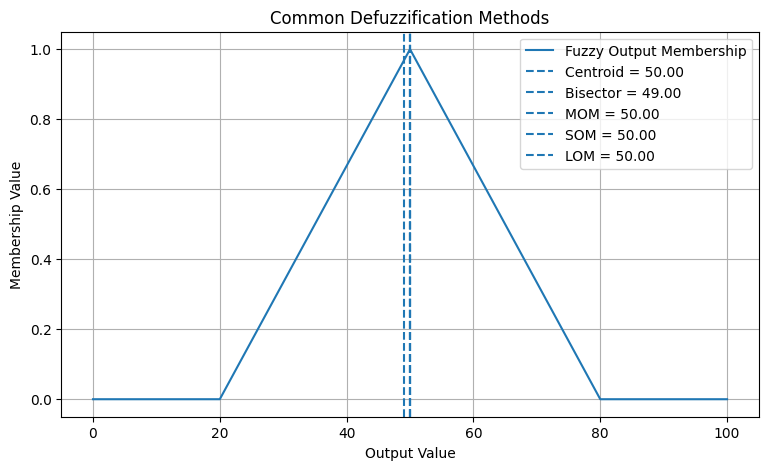

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

# Load Breast Cancer Dataset

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Features:", data.feature_names)

# Select Mean Radius Feature

radius = X[:, 0]

print("\nFirst 10 Radius Values:")
print(radius[:10])

# Fuzzy Membership Function

def high_membership(x):
    if x <= 10:
        return 0
    elif x >= 20:
        return 1
    else:
        return (x - 10) / (20 - 10)

print("\nSample Membership Values:")

for r in [8, 12, 15, 18, 20]:
    print(r, high_membership(r))

# Create Fuzzy Output Set

risk = np.arange(0, 101, 1)

membership = np.zeros(len(risk))

for i, r in enumerate(risk):

    # Rising part
    if 20 <= r <= 50:
        membership[i] = (r - 20) / 30

    # Falling part
    elif 50 < r <= 80:
        membership[i] = (80 - r) / 30

    # Outside fuzzy region
    else:
        membership[i] = 0

# 1. Centroid Method

centroid = np.sum(risk * membership) / np.sum(membership)

# 2. Bisector Method

total_area = np.sum(membership)

cumulative_area = np.cumsum(membership)

bisector_index = np.argmin(
    np.abs(cumulative_area - total_area / 2)
)

bisector = risk[bisector_index]

# 3. Mean of Maximum (MOM)

max_membership = np.max(membership)

max_values = risk[membership ==
max_membership]

mom = np.mean(max_values)

# 4. Smallest of Maximum (SOM)

som = np.min(max_values)

# 5. Largest of Maximum (LOM)

lom = np.max(max_values)

# Display Results

print("\nDefuzzification Results")
print("-----------------------------")

print("Centroid (COG):", round(centroid, 2))



print("Bisector:", round(bisector, 2))
print("Mean of Maximum (MOM):", round(mom,
2))
print("Smallest of Maximum (SOM):",
round(som, 2))
print("Largest of Maximum (LOM):", round(lom,
2))

# Plot Fuzzy Membership Function

plt.figure(figsize=(9, 5))

plt.plot(
    risk,
    membership,
    label="Fuzzy Output Membership"
)

# Defuzzified values

plt.axvline(
    centroid,
    linestyle="--",
    label=f"Centroid = {centroid:.2f}"
)

plt.axvline(
    bisector,
    linestyle="--",
    label=f"Bisector = {bisector:.2f}"
)

plt.axvline(
    mom,
    linestyle="--",
    label=f"MOM = {mom:.2f}"
)

plt.axvline(
    som,
    linestyle="--",
    label=f"SOM = {som:.2f}"
)

plt.axvline(
    lom,
    linestyle="--",
    label=f"LOM = {lom:.2f}"
)

plt.title("Common Defuzzification Methods")
plt.xlabel("Output Value")
plt.ylabel("Membership Value")
plt.legend()
plt.grid(True)

plt.show()